# Phân đoạn ảnh (Image Segmentation) bằng U-Net
Bài toán: với mỗi **pixel** của ảnh, dự đoán nó thuộc lớp nào (khác phân loại ảnh chỉ cho 1 nhãn cho cả ảnh).

Dữ liệu: **Oxford-IIIT Pet** (ảnh chó, mèo + mask từng pixel). Mỗi pixel thuộc 1 trong 3 lớp:
- `pet`: vùng con vật
- `background`: nền
- `border`: đường viền giữa con vật và nền (khó nhất vì rất mỏng)

Mô hình: **U-Net** tự xây, train từ đầu.

In [ ]:
import torch
import common as C
print(C.DEVICE)

## 1. Dữ liệu
Ảnh được resize về 128×128 (mask dùng nội suy gần nhất để không tạo nhãn lẻ). Lần chạy đầu sẽ tạo cache nên mất khoảng 1 phút.

In [ ]:
IMG_SIZE, BATCH_SIZE = 128, 32
loaders = C.get_loaders(IMG_SIZE, BATCH_SIZE)
print({k: len(v.dataset) for k, v in loaders.items()})
C.show_samples(loaders['val'])

In [ ]:
# Tỉ lệ pixel mỗi lớp: nền chiếm nhiều nhất, viền ít nhất
C.class_pixel_ratio(loaders['val'])

## 2. Mô hình U-Net
Kiến trúc hình chữ **U**:

- **Encoder (đường xuống)**: 4 lần `DoubleConv → MaxPool`. Kích thước giảm một nửa, số kênh tăng gấp đôi (128→64→32→16→8; kênh 32→64→128→256→512). Học "ảnh có gì".
- **Bottleneck**: tầng sâu nhất (8×8×512), đặc trưng trừu tượng nhất.
- **Decoder (đường lên)**: 4 lần `ConvTranspose (nhân đôi kích thước) → ghép skip → DoubleConv`. Khôi phục lại kích thước 128×128. Học "chúng nằm ở đâu".
- **Skip connection**: nối đặc trưng của encoder cùng độ phân giải sang decoder. Encoder biết *vị trí chính xác* (nhưng ít ngữ nghĩa), decoder biết *ngữ nghĩa* (nhưng mất chi tiết); ghép lại cho ranh giới sắc nét.
- **Lớp cuối**: Conv 1×1 chuyển 32 kênh thành 3 kênh = điểm số cho 3 lớp ở **mỗi pixel**.

In [ ]:
model = C.UNet(n_classes=3, base=32)
print(f'{sum(p.numel() for p in model.parameters())/1e6:.2f}M tham số')

In [ ]:
# Theo dõi kích thước tensor qua encoder và đầu ra
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
print('input  ', tuple(x.shape))
for k, blk in enumerate(model.enc):
    x = blk(x)
    print(f'enc {k}  ', tuple(x.shape))
    if k < 4:
        x = model.pool(x)
print('output ', tuple(model(torch.randn(1, 3, IMG_SIZE, IMG_SIZE)).shape), '-> (batch, lớp, cao, rộng)')

## 3. Huấn luyện
- **Loss = CrossEntropy + Dice loss.** CrossEntropy phân loại từng pixel; Dice loss đo độ chồng lấp giữa vùng dự đoán và vùng thật, giúp lớp nhỏ như `border` không bị bỏ qua.
- AdamW + OneCycleLR, mixed precision. Chọn checkpoint theo **val mIoU**.

In [ ]:
EPOCHS, LR = 30, 2e-3
model, hist, t = C.train_model('unet', model, loaders, EPOCHS, LR)
print(f'Thời gian train: {t/60:.1f} phút')

In [ ]:
C.plot_history(hist)

## 4. Đánh giá trên tập test (3.669 ảnh chính thức)
- **Pixel accuracy**: tỉ lệ pixel đoán đúng (dễ bị nền chi phối nên không đủ).
- **IoU** (Intersection over Union) = vùng chung / vùng hợp của dự đoán và thật. **mIoU** là trung bình các lớp, đây là chỉ số chính.
- **Dice** = 2 × vùng chung / (tổng hai vùng), luôn lớn hơn hoặc bằng IoU.

In [ ]:
res = C.evaluate('unet', model, loaders['test'], hist, t)

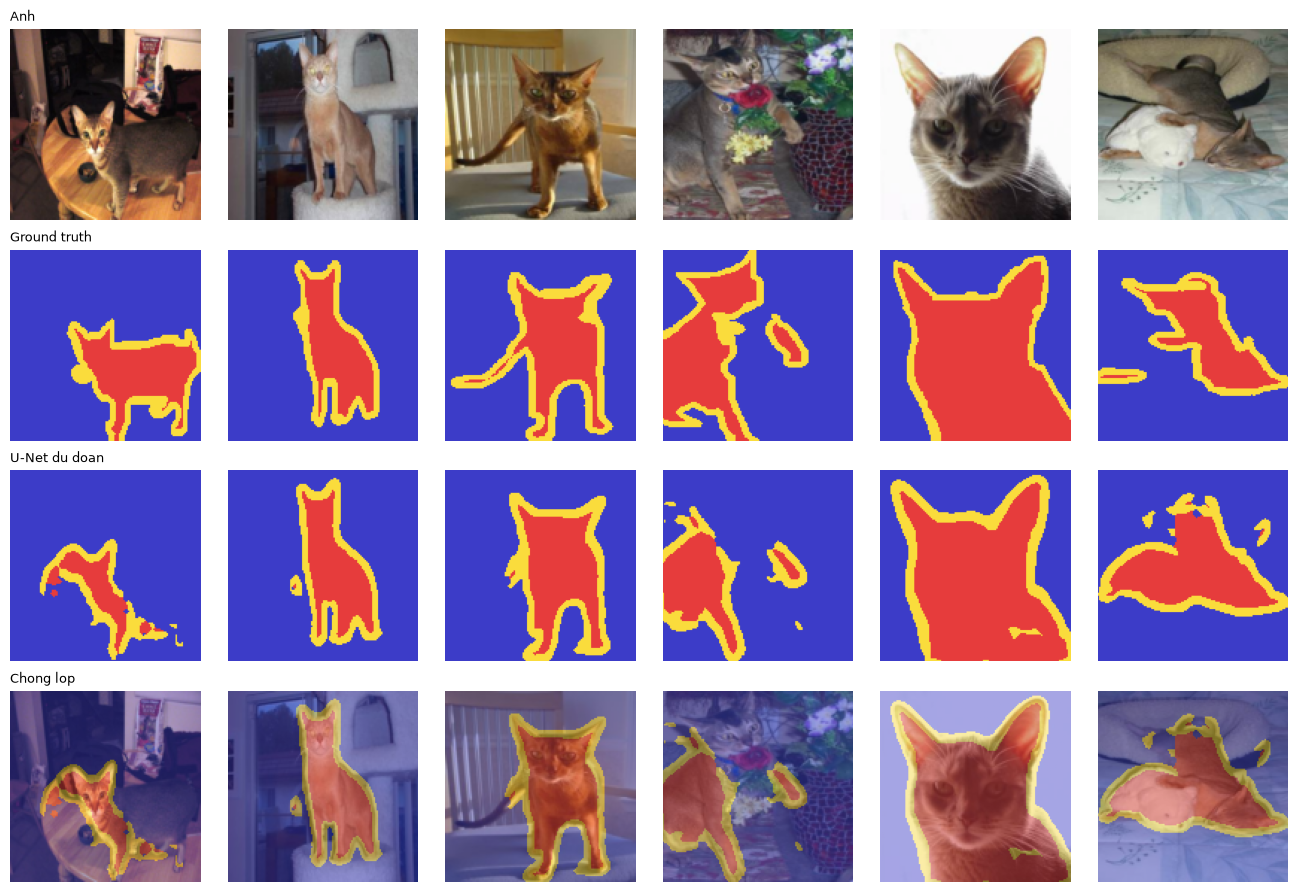

In [10]:
C.show_predictions(model, loaders['test'], n=6)

## 5. Nhận xét

**Kết quả trên tập test (3.669 ảnh):** U-Net đạt **pixel accuracy 91,3%**, **mIoU = 0,767** và **mDice = 0,859** (7,76 triệu tham số, train 30 epoch, khoảng 10,7 phút, từ đầu, không pretrained).

| Lớp | IoU | Dice |
|---|---|---|
| `background` | 0,914 | 0,955 |
| `pet` | 0,839 | 0,913 |
| `border` | 0,548 | 0,708 |

**Theo từng lớp:** nền và con vật được phân đoạn tốt (IoU từ 0,84 đến 0,91). Lớp `border` kém hơn nhiều (IoU 0,548) và kéo mIoU xuống. Nguyên nhân hợp lý là viền chỉ rộng vài pixel và chỉ chiếm khoảng 11% số pixel, nên lệch vài pixel là IoU giảm mạnh; ngoài ra ranh giới viền trong dữ liệu gốc vốn được gán nhãn thủ công, không thật sự chính xác. Pixel accuracy (91,3%) cao hơn mIoU rõ rệt vì bị lớp nền chiếm nhiều pixel chi phối, do đó **mIoU là chỉ số đáng tin hơn**.

**Quá trình huấn luyện:** val mIoU tăng từ 0,456 lên 0,765, loss giảm đều. Train mIoU cuối là 0,816, val là 0,765, chênh khoảng 5 điểm nên mô hình có **overfit nhẹ** nhưng vẫn chấp nhận được. Ở khoảng 8 epoch cuối, val mIoU gần như phẳng (0,762 đến 0,765) do learning rate đã giảm gần 0 theo OneCycleLR, nên train thêm epoch với cấu hình này ít có khả năng cải thiện nhiều. Val loss dao động ở nửa đầu khi learning rate còn cao, và ổn định ở nửa sau.

**Kết luận:** U-Net tự xây, train từ đầu chỉ trong 10 phút, đã tách con vật khỏi nền khá tốt. Skip connection giúp giữ được ranh giới sắc nét giữa các vùng lớn. Điểm yếu chính là lớp `border` mỏng.

**Hướng cải thiện:**
- Tăng `IMG_SIZE` lên 256 để viền có nhiều pixel hơn.
- Dùng encoder pretrained (ví dụ ResNet làm encoder cho U-Net), thường tăng mIoU đáng kể khi dữ liệu ít.
- Tăng trọng số cho lớp `border` trong loss, hoặc thêm augmentation (xoay, co giãn).

*Lưu ý: đây là kết quả một lần chạy với một seed. Các lý giải về nguyên nhân (viền mỏng, nhãn viền không chính xác) là suy luận từ số liệu, chưa kiểm chứng riêng bằng thực nghiệm.*